#### **Stock Health, Net Available Stock & ABC-XYZ Segmentation**

- This notebook evaluates current spare-parts stock positions, reconciles Net Available Stock (`On Hand + Due In - Reserved - Unserviceable`), classifies SKUs across ABC (value share) and XYZ (demand stability), and quantifies working capital tied up in excess or slow-moving stock in AED.

#### **Environment & Module Setup**

In [1]:
import sys
from pathlib import Path
import pandas as pd
import plotly.express as px

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.inventory_metrics import compute_stock_positions, classify_abc_xyz

raw_dir = PROJECT_ROOT / "data" / "raw"
inv_raw = pd.read_csv(raw_dir / "inventory_snapshot.csv")
po_raw = pd.read_csv(raw_dir / "open_purchase_orders.csv")

metrics_df = classify_abc_xyz(compute_stock_positions(inv_raw, po_raw))
print(f"Evaluated {len(metrics_df)} spare parts across {metrics_df['hub_location'].nunique()} UAE hubs.")

Evaluated 28 spare parts across 3 UAE hubs.


#### **Net Available Stock & Valuation Summary (AED)**

In [3]:
pos_cols = [
    "part_number",
    "part_name",
    "hub_location",
    "on_hand_qty",
    "due_in_qty",
    "reserved_qty",
    "unserviceable_qty",
    "net_available_stock",
    "net_days_of_supply",
    "on_hand_value_aed",
    "net_available_value_aed",
]
display(metrics_df[pos_cols].head(5))

print("\n=== Portfolio Valuation Totals (AED) ===")
summary_totals = pd.DataFrame(
    {
        "Metric": [
            "On-Hand Stock Value",
            "Due-In Pipeline Value",
            "Reserved Stock Value",
            "Unserviceable / Core Value",
            "Net Available Stock Value",
            "Annual Demand Value (Run-Rate)",
        ],
        "AED": [
            metrics_df["on_hand_value_aed"].sum(),
            metrics_df["due_in_value_aed"].sum(),
            metrics_df["reserved_value_aed"].sum(),
            metrics_df["unserviceable_value_aed"].sum(),
            metrics_df["net_available_value_aed"].sum(),
            metrics_df["annual_usage_value_aed"].sum(),
        ],
    }
)
summary_totals["AED"] = summary_totals["AED"].map(lambda x: f"AED {x:,.2f}")
display(summary_totals)

,part_number,part_name,hub_location,on_hand_qty,due_in_qty,reserved_qty,unserviceable_qty,net_available_stock,net_days_of_supply,on_hand_value_aed,net_available_value_aed
0,PRT-001,Heavy-Duty Engine Oil Filter,Jebel Ali Hub,46,0,4,1,41,25.625000,4370.0,3895.0
1,PRT-002,Primary Fuel Water Separator,Jebel Ali Hub,6,17,6,1,16,14.117647,990.0,2640.0
2,PRT-003,Cabin Air Filter Element,Sajaa Hub,25,0,3,1,21,15.000000,1375.0,1155.0
3,PRT-004,Heavy-Duty Air Intake Filter,Mussafah Hub,18,0,2,0,16,18.461538,3780.0,3360.0
4,PRT-005,Front Disc Brake Pad Set,Jebel Ali Hub,6,15,6,1,14,14.000000,2880.0,6720.0



=== Portfolio Valuation Totals (AED) ===


,Metric,AED
0,On-Hand Stock Value,"AED 387,740.00"
1,Due-In Pipeline Value,"AED 17,240.00"
2,Reserved Stock Value,"AED 38,890.00"
3,Unserviceable / Core Value,"AED 11,880.00"
4,Net Available Stock Value,"AED 354,210.00"
5,Annual Demand Value (Run-Rate),"AED 3,234,996.00"


#### **ABC-XYZ Segmentation Matrix & Hub Breakdown**

In [4]:
abc_xyz_pivot = pd.crosstab(
    metrics_df["abc_class"],
    metrics_df["xyz_class"],
    margins=True,
    margins_name="Total SKUs",
)
print("=== ABC-XYZ SKU Count Matrix ===")
display(abc_xyz_pivot)

abc_xyz_val = (
    metrics_df.groupby(["abc_class", "xyz_class", "abc_xyz_segment"], as_index=False)
    .agg(
        sku_count=("part_number", "count"),
        on_hand_value_aed=("on_hand_value_aed", "sum"),
        annual_usage_aed=("annual_usage_value_aed", "sum"),
    )
    .sort_values("annual_usage_aed", ascending=False)
)
display(abc_xyz_val)

=== ABC-XYZ SKU Count Matrix ===


xyz_class,X,Y,Z,Total SKUs
abc_class,,,,
A,6,6,1,13
B,5,3,1,9
C,4,2,0,6
Total SKUs,15,11,2,28


,abc_class,xyz_class,abc_xyz_segment,sku_count,on_hand_value_aed,annual_usage_aed
0,A,X,AX,6,91230.0,1715880.0
1,A,Y,AY,6,57490.0,738660.0
3,B,X,BX,5,57650.0,285600.0
4,B,Y,BY,3,89780.0,189840.0
6,C,X,CX,4,39320.0,110280.0
2,A,Z,AZ,1,2450.0,82320.0
5,B,Z,BZ,1,33880.0,59136.0
7,C,Y,CY,2,15940.0,53280.0


#### **Slow-Moving & High-DOS Stock Audit**

Slow-moving / high-DOS parts identified: 7


,part_number,part_name,abc_xyz_segment,months_since_last_issue,on_hand_qty,net_available_stock,net_days_of_supply,on_hand_value_aed
25,PRT-026,EGR Valve Assembly,BY,7,41,40,266.666667,45920.0
15,PRT-016,LED Headlamp Assembly,BX,1,98,97,242.500000,42140.0
18,PRT-019,Air Suspension Spring Bellow,BY,1,63,63,198.947368,35280.0
22,PRT-023,Transmission Oil Cooler,BZ,1,22,22,206.250000,33880.0
10,PRT-011,Thermostat & Housing Kit,CX,3,162,161,254.210526,23490.0
23,PRT-024,Differential Pinion Seal Kit,CX,8,100,99,297.000000,12500.0
27,PRT-028,Side Mirror Housing Assembly,CY,2,38,36,270.000000,11020.0


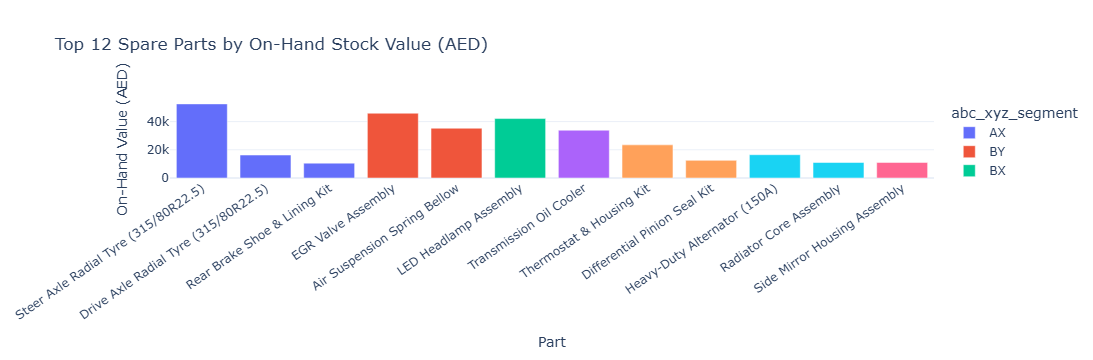

In [5]:
slow_df = metrics_df[metrics_df["is_slow_moving"] | (metrics_df["net_days_of_supply"] > 180)].copy()
slow_cols = [
    "part_number",
    "part_name",
    "abc_xyz_segment",
    "months_since_last_issue",
    "on_hand_qty",
    "net_available_stock",
    "net_days_of_supply",
    "on_hand_value_aed",
]
print(f"Slow-moving / high-DOS parts identified: {len(slow_df)}")
display(slow_df[slow_cols].sort_values("on_hand_value_aed", ascending=False))

fig = px.bar(
    metrics_df.sort_values("on_hand_value_aed", ascending=False).head(12),
    x="part_name",
    y="on_hand_value_aed",
    color="abc_xyz_segment",
    title="Top 12 Spare Parts by On-Hand Stock Value (AED)",
    labels={"on_hand_value_aed": "On-Hand Value (AED)", "part_name": "Part"},
)
fig.update_layout(xaxis_tickangle=-35, template="plotly_white")
fig.show()

#### **Key Findings & Developer Credit**

##### **Key Takeaways:**
* Reconciling `Reserved` and `Unserviceable` stock prevents overstating immediately usable inventory during workshop peaks.
* Combining ABC value share with XYZ demand variability highlights high-value erratic (`AZ`) and slow-moving (`CZ`) SKUs that need tailored buffer and disposal strategies.

**Developed by Aklilu Abera Dana | Supply Chain Data Analyst**